<a href="https://colab.research.google.com/github/emmanguyen01-spec/Ad-Optimization-Agent/blob/main/ad_optimization_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ad Optimization Agent

This notebook builds a small, explainable agent that recommends daily advertising budgets for Search, Social, and Display. It uses mock CSV data and does not require an API key.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from ad_optimization_agent import AdOptimizationAgent

# In Colab, upload ad_optimization_agent.py and ad_campaign_data.csv first.
CSV_PATH = 'ad_campaign_data.csv'
agent = AdOptimizationAgent()
print(agent.show_system_prompt())

You are an explainable advertising budget optimization agent.
Use prior campaign performance to recommend the next day's budget across Search,
Social, and Display. Maximize expected conversions, obey every budget guardrail,
and explain each recommendation in plain language. Never use future data.


In [2]:
data = agent.read_data(CSV_PATH)
print(f'Rows: {len(data)}')
print(f'Dates: {data.date.min().date()} through {data.date.max().date()}')
display(data.head())

Rows: 63
Dates: 2026-09-01 through 2026-09-21


,date,channel,spend,impressions,clicks,conversions
0,2026-09-01,Display,100,40000,400,6
1,2026-09-01,Search,100,20000,900,27
2,2026-09-01,Social,100,25000,700,14
3,2026-09-02,Display,100,40500,405,6
4,2026-09-02,Search,100,19800,890,26


## 1. Calculate performance metrics

CTR is clicks divided by impressions. CVR is conversions divided by clicks. Conversion yield is conversions divided by spend, which this agent uses to compare channels.

In [3]:
metrics = agent.calculate_metrics(data)
display(metrics.round(4))

,channel,spend,impressions,clicks,conversions,ctr,cvr,conversion_yield,cpa
0,Display,2100,934800,9430,165,0.0101,0.0175,0.0786,12.7273
1,Search,2100,462800,20965,702,0.0453,0.0335,0.3343,2.9915
2,Social,2100,569000,16770,383,0.0295,0.0228,0.1824,5.4830


## 2. Recommend budgets with guardrails

The agent uses only earlier dates when making each recommendation. It keeps the total at $300, gives every channel at least $60, caps a channel at $180, and limits daily movement to 20%.

In [4]:
allocations, decision_log = agent.recommend_budgets(data)
final_date = allocations['date'].max()
print(f'Final recommendation date: {final_date}')
display(allocations[allocations['date'] == final_date].round(2))
display(decision_log.head(9))

Final recommendation date: 2026-09-21


,date,channel,recommended_budget
60,2026-09-21,Search,151.05
61,2026-09-21,Social,88.95
62,2026-09-21,Display,60.00


,date,channel,previous_budget,recommended_budget,reason
0,2026-09-01,Search,100.000000,100.000000,Search stayed near $100.00 because the change ...
1,2026-09-01,Social,100.000000,100.000000,Social stayed near $100.00 because the change ...
2,2026-09-01,Display,100.000000,100.000000,Display stayed near $100.00 because the change...
3,2026-09-02,Search,100.000000,122.546689,Search increased by $22.55 because its prior c...
4,2026-09-02,Social,100.000000,93.208829,Social decreased by $6.79 to fund stronger cha...
5,2026-09-02,Display,100.000000,84.244482,Display decreased by $15.76 to fund stronger c...
6,2026-09-03,Search,122.546689,143.725031,Search increased by $21.18 because its prior c...
7,2026-09-03,Social,93.208829,89.162358,Social decreased by $4.05 to fund stronger cha...
8,2026-09-03,Display,84.244482,67.112611,Display decreased by $17.13 to fund stronger c...


## 3. Compare with an equal-split baseline

In [5]:
comparison, detail = agent.evaluate(data, allocations)
display(comparison.round(4))
agent_row = comparison.loc[comparison.strategy == 'Optimized agent'].iloc[0]
baseline_row = comparison.loc[comparison.strategy == 'Equal-split baseline'].iloc[0]
print(f"Expected conversion lift: {agent_row.conversion_lift_vs_baseline:.2%}")
print(f"CPA difference: ${agent_row.blended_cpa - baseline_row.blended_cpa:.2f}")

,strategy,expected_conversions,spend,blended_cpa,conversion_lift_vs_baseline
0,Optimized agent,1486.5619,6300.0,4.238,0.1892
1,Equal-split baseline,1250.0000,6300.0,5.040,0.0000


Expected conversion lift: 18.92%
CPA difference: $-0.80


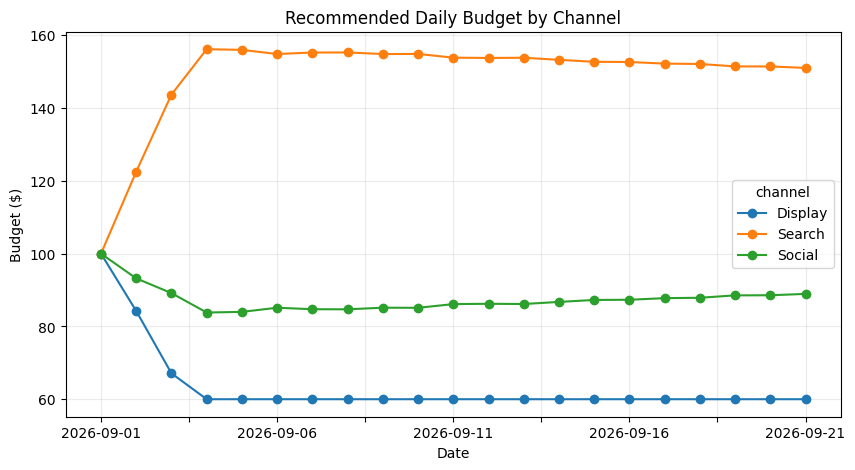

In [6]:
# Visualize the agent's budget recommendations over time.
budget_plot = allocations.pivot(index='date', columns='channel', values='recommended_budget')
budget_plot.plot(figsize=(10, 5), marker='o')
plt.title('Recommended Daily Budget by Channel')
plt.ylabel('Budget ($)')
plt.xlabel('Date')
plt.grid(alpha=0.25)
plt.show()

## Conclusion

The agent shifts budget toward channels with stronger prior conversion yield, but the guardrails prevent sudden or extreme changes. The decision log makes each recommendation reviewable by a human.